# Лабораторная 3. Обучение языковой модели руками

Ноутбук читает артефакты из `lab03/artifacts/` (их создаёт `run.py`) и строит график и таблицы для README. Обучение здесь не запускается.

Лосс на одной позиции окна, где $x_t$ настоящий токен, а $x_{<t}$ всё, что левее:

$$\mathcal{L}=-\frac{1}{N}\sum_{t=1}^{N}\ln p_\theta\left(x_t\mid x_{<t}\right)$$

На случайных весах распределение почти равномерное, поэтому начальный лосс близок к $\ln V$, где $V$ размер словаря.

In [2]:
import csv, json, math
from pathlib import Path
import matplotlib.pyplot as plt

ART = next(p for p in (Path("artifacts"), Path("lab03/artifacts")) if p.exists())
load = lambda name: json.loads((ART / name).read_text(encoding="utf-8"))
cfg, samples, gen = load("tiny_config.json"), load("samples.json"), load("generation.json")
with open(ART / "train_curve.csv", encoding="utf-8") as f:
    curve = [{k: float(v) for k, v in r.items()} for r in csv.DictReader(f)]
print(json.dumps(cfg, ensure_ascii=False, indent=1))
print("ln V =", round(math.log(cfg["vocab_size"]), 4), "| train_loss на шаге 0 =", curve[0]["train_loss"])

{
 "vocab_size": 1534,
 "d_model": 128,
 "n_layers": 4,
 "n_heads": 4,
 "d_ff": 512,
 "context": 128,
 "n_params": 1202432,
 "steps": 2000,
 "batch": 32,
 "lr": 0.001,
 "seed": 0,
 "train_tokens": 753537,
 "val_tokens": 83461,
 "bpe_merges": 1500,
 "train_minutes": 0.3,
 "device": "cuda"
}
ln V = 7.3356 | train_loss на шаге 0 = 7.366


## Кривая обучения

`train_loss` на каждой строке это среднее по шагам прошедшего отрезка, а `val_loss` считается на 20 фиксированных окнах отложенной части сразу после шага. Поэтому в начале `train_loss` выше `val_loss`: в среднее по отрезку входят ещё необученные шаги.

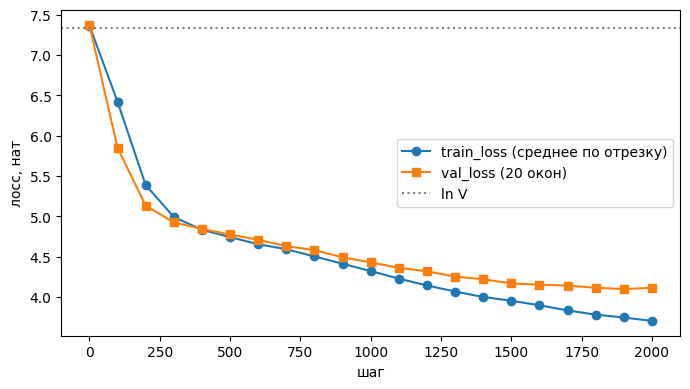

падение val_loss: 3.257 | минимум val_loss 4.1001 на шаге 1900
val - train на последнем шаге: 0.4107


In [3]:
steps = [r["step"] for r in curve]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(steps, [r["train_loss"] for r in curve], marker="o", label="train_loss (среднее по отрезку)")  # лосс первого батча
ax.plot(steps, [r["val_loss"] for r in curve], marker="s", label="val_loss (20 окон)")
ax.axhline(math.log(cfg["vocab_size"]), color="gray", linestyle=":", label="ln V")  # равновероятный выбор
ax.set_xlabel("шаг"); ax.set_ylabel("лосс, нат"); ax.legend(); fig.tight_layout()
fig.savefig(ART / "train_curve.png", dpi=150); plt.show()
best = min(curve, key=lambda r: r["val_loss"])
print("падение val_loss:", round(curve[0]["val_loss"] - curve[-1]["val_loss"], 4), "| минимум val_loss", best["val_loss"], "на шаге", int(best["step"]))
print("val - train на последнем шаге:", round(curve[-1]["val_loss"] - curve[-1]["train_loss"], 4))

## Образцы по шагам

Затравка одна, температура $0.8$. Перед каждым образцом выставлен один и тот же seed, поэтому случайные числа совпадают, и сходство начал образцов на разных шагах может быть следствием этого, а не обучения.

In [4]:
for s in samples["samples"]:
    print(f"шаг {s['step']}:", s["text"], "\n")

шаг 0: князь андрей дал вечершадля пьервидимо адэтим ю видеть только ры отношстарораз ез гами францвольно сами шком нии голоэтоник толмолодоон день ги надедеехали тихстраым сознавсегда влсти огромрешидаже мночастдолго соня стуый баые вперед ами себдобвопрос своего варграфиня нул 

шаг 100: князь андрей это князь шачных и в что ю видеть только ута старорпными вин и прирявша на толском и ненадедералинной овления выйное некм и стуме-то хорошенлен и в своего и снул 

шаг 500: князь андрей это никогда не могу будет сделав что ю видеть только удобрался прусского которые хотел приемышения где мне он не отвечать а как ты этого при сознания маршался так даже непременно может не метом что какая же добно средства и 

шаг 2000: князь андрей это никогда не могу просить его что ю так только она не любит ли он бы люблю и приблизил себе своей жизни и он не мог понять его как ни страдать сознанюю и решительностью и не мешает ли какая мерзадахаться так дур 



## Режимы генерации

Температура $T$ делит логиты $z_i$ перед softmax:

$$p_i=\frac{e^{z_i/T}}{\sum_j e^{z_j/T}}$$

При $T\to 0$ остаётся самый вероятный токен (жадный выбор), при $T>1$ распределение сплющивается. Top-$p$ оставляет наименьший набор токенов с суммой вероятностей не меньше $p$ и перенормирует его.

In [5]:
def first_repeat(ids, n=4):  # начало первой повторившейся четвёрки
    seen = set()
    for i in range(n, len(ids) + 1):
        g = tuple(ids[i - n:i])
        if g in seen:
            return i - n
        seen.add(g)
    return None

print(f"{'режим':10} {'T':>4} {'top_p':>6} {'токенов':>8} {'loop_start':>11}")
for r in gen["runs"]:
    print(f"{r['name']:10} {r['temperature']:>4} {str(r['top_p']):>6} {r['n_tokens']:>8} {str(r.get('loop_start', '-')):>11}")
greedy = next(r for r in gen["runs"] if r["name"] == "greedy")
print("\nпересчёт loop_start по ids:", first_repeat(greedy["ids"]))
for r in gen["runs"]:
    print(f"\n[{r['name']}]", r["text"])

режим         T  top_p  токенов  loop_start
greedy      0.0   None       80          17
t0.7        0.7   None       80           -
t1.5        1.5   None       80           -
top_p0.9    1.0    0.9       80           -

пересчёт loop_start по ids: 17

[greedy] чувствовал что ему казалось что он не мог удержать его в себе и не мог не мог удержать его в себе и не мог понять того что он видел в его душе его он чувствовал как он чувствовал как и не чувствовал это и не только не понимал его он чувствовал что он чувствовал это и не мог не мог удержаться и не мог удержаться и не мог у

[t0.7] это не мог сказать но как бы желать видеть только она не могла удержать того что это было теперь не могло быть иться он не отвечает а как ни предполагал но и не могу понять ни того что не мешать какая я думаю что она не может приказываться к наташе но она подождет это за что он это не было то что

[t1.5] это никогда наполеон для наполеона со стороны по ю видеть только усиливало свою ввольно и примиранию

## Бонусы

In [6]:
from IPython.display import Image, display
if (ART / "eval.json").exists():
    ev = load("eval.json")
    print("слов:", ev["words"])
    for m in ("bigram", "tiny", "qwen"):
        print(f"{m:7} токенов {ev[m]['tokens']:>5}  нат/слово {ev[m]['nats_per_word']:>7}  ppl/слово {ev[m]['ppl_per_word']}")
if (ART / "speed.csv").exists():
    print(Path(ART / "speed.csv").read_text(encoding="utf-8"))
if (ART / "scaling.png").exists():
    display(Image(filename=str(ART / "scaling.png")))

слов: 2000
bigram  токенов  1999  нат/слово  8.4151  ppl/слово 4514.7
tiny    токенов  3665  нат/слово  7.5615  ppl/слово 1922.8
qwen    токенов  3870  нат/слово  5.6218  ppl/слово 276.4
mode,new_tokens,seconds,tokens_per_second
cache,64,1.773,36.1
no_cache,64,2.059,31.08



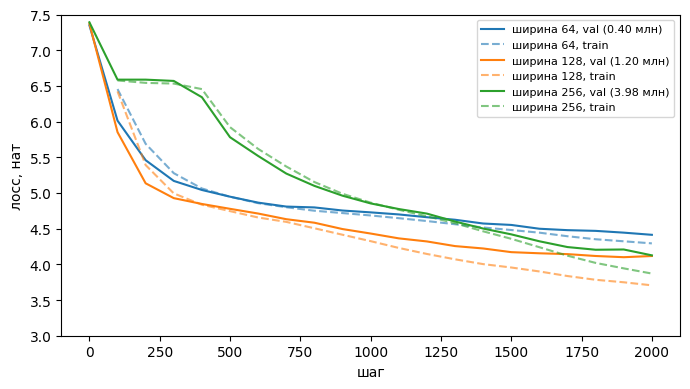

In [7]:
with open(ART / "scaling.csv", encoding="utf-8") as f:
    rows = list(csv.DictReader(f))
steps = [int(r["step"]) for r in rows]
n_params = {w: load("scaling.json")[w]["n_params"] for w in ("64", "128", "256")}  # параметры из scaling.json
fig, ax = plt.subplots(figsize=(7, 4))
for w in ("64", "128", "256"):
    line, = ax.plot(steps, [float(r[f"val_loss_{w}"]) for r in rows], label=f"ширина {w}, val ({n_params[w] / 1e6:.2f} млн)")
    tr = [(s, float(r[f"train_loss_{w}"])) for s, r in zip(steps, rows) if r[f"train_loss_{w}"]]  # на шаге 0 train пустой
    ax.plot([s for s, _ in tr], [v for _, v in tr], "--", color=line.get_color(), alpha=0.6, label=f"ширина {w}, train")
ax.set_xlabel("шаг"); ax.set_ylabel("лосс, нат"); ax.set_ylim(3, 7.5); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(ART / "scaling.png", dpi=150); plt.show()